# FRED external drone evaluation

This notebook records the November 21, 2026 evaluation of SkyGuard and all
three tracking presets on the official FRED test split, including the full
configured v0.883 boosted RGB preset. Start with the saved
run to see the measured results. Set `RUN_MODE = "rerun"` to run the same
checkpoints and scoring again on the prepared clips.

Use the **Python (Drone Tracking v2)** kernel. From the repository root, open
this notebook with `uv run jupyter lab notebooks/fred_external_evaluation.ipynb`.

In [1]:
import json
import sys
from io import BytesIO
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display
from scipy.optimize import linear_sum_assignment

ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents) if (path / "run_video.py").is_file()),
    None,
)
if ROOT is None:
    raise RuntimeError("Open the notebook in the Drone Tracking v2 repository.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from eval_track import load_ids
from score import evaluate, iou

SAVED_RUN = ROOT / "preds" / "fred_evaluation" / "overview-20261121-105028"
DATASET = ROOT / "drone_data" / "fred_test"
PRACTICE_SCORES = ROOT / "preds" / "experiments" / "20261121-101320-d88v4swu" / "mot_metrics.csv"

RUN_MODE = "saved"  # "saved" reads the archived results. "rerun" runs all three presets.
RERUN_CLIPS = ()  # Empty uses all eight. Otherwise list clip names, e.g. ("fred-65-entry",).
PREVIEW_CLIPS = ("fred-65-entry", "fred-115-middle", "fred-21-middle")
PREVIEW_PRESET = "v0.883-boosted"

if RUN_MODE not in {"saved", "rerun"}:
    raise ValueError('RUN_MODE must be "saved" or "rerun".')
manifest_path = SAVED_RUN / "benchmark.json"
if not manifest_path.is_file():
    manifest_path = DATASET / "benchmark.json"
if not manifest_path.is_file():
    raise FileNotFoundError(f"Restore benchmark.json at {SAVED_RUN} or {DATASET}.")
BENCHMARK = json.loads(manifest_path.read_text(encoding="utf-8"))
CLIPS = pd.DataFrame(BENCHMARK["clips"]).set_index("clip").sort_index()
PRESETS = [item["name"] for item in BENCHMARK["experiments"]]

Matplotlib is building the font cache; this may take a moment.


## 1. Dataset and preparation

FRED is the Florence RGB-Event Drone Dataset. The authors report more than
seven hours of annotated recordings across five drone models, with synchronized
RGB frames and event-camera streams. This benchmark uses RGB footage from the
official test split. [FRED project](https://miccunifi.github.io/FRED/)

Sequences 21, 111 and 115 were the three smallest test archives and cover dusk
or night. Sequence 65 adds daylight footage with two target IDs. This is a
small sample from four recordings.

Use the counts below to distinguish total frames from frames with labeled
drones. Every two-drone frame in this sample comes from sequence 65. Lighting,
target size and the number of targets vary together across these recordings.
FRED is outside the repository's documented training sources. SkyGuard's
training image list is undisclosed, so prior exposure remains unverified.
[Official test split](https://huggingface.co/datasets/GabrieleMagrini/FRED/tree/main/test) ·
[Format and paper](https://github.com/miccunifi/FRED) ·
[SkyGuard model card](https://huggingface.co/SkyGuardAI/drone-detection-yolov11)

Each sequence contributes two 180-frame windows at 30 fps. The entry window
starts 30 frames before the first labeled box, with frame 1 as the lower bound.
The middle window starts 90 frames before the integer median of labeled
source-frame numbers. Window selection used the annotations before inference.

Source files were read in timestamp order. Each `coordinates_rgb.txt`
timestamp maps to a one-based source frame via `round(seconds / 0.033333)`.
Reference boxes were clipped to the 1280 × 720 image bounds. Frames and boxes
were then scaled by 1.5 to 1920 × 1080 for the offline tracker. The prepared
clips preserve the published track IDs and use the pipeline's
`<clip>/video.mp4` and `<clip>/gt/gt.txt` layout.

Box sizes below are expressed in native 1280 × 720 source pixels.

In [2]:
reference_by_clip = {}
frame_rows = []
native_box_rows = []
source_width, source_height = BENCHMARK["source_size_xy"]
video_width, video_height = BENCHMARK["converted_size_xy"]
fps = BENCHMARK["fps"]

for clip, metadata in CLIPS.iterrows():
    path = DATASET / clip / "gt" / "gt.txt"
    if not path.is_file():
        raise FileNotFoundError(path)
    labels = load_ids(path, False)
    reference_by_clip[clip] = labels
    n_frames = int(metadata["frames"])
    label_counts = np.array([len(labels.get(frame, ())) for frame in range(1, n_frames + 1)])
    if label_counts.sum() != metadata["gt_boxes"] or len(labels) != metadata["gt_frames"]:
        raise ValueError(f"Ground-truth counts differ from the manifest for {clip}.")
    frame_rows.append({
        "Excerpt": clip, "Lighting": metadata["lighting"], "Frames": n_frames,
        "Seconds": n_frames / fps, "0 labeled": int((label_counts == 0).sum()),
        "1 labeled": int((label_counts == 1).sum()), "2 labeled": int((label_counts == 2).sum()),
        "GT boxes": int(label_counts.sum()),
    })
    for boxes in labels.values():
        for left, top, right, bottom, *_ in boxes:
            native_box_rows.append({
                "Lighting": metadata["lighting"],
                "Width (px)": (right - left) * source_width / video_width,
                "Frame area (%)": 100 * (right - left) * (bottom - top) / (video_width * video_height),
            })

coverage = pd.DataFrame(frame_rows).set_index("Excerpt")
by_lighting = coverage.groupby("Lighting")[[
    "Frames", "Seconds", "0 labeled", "1 labeled", "2 labeled", "GT boxes",
]].sum()
by_lighting.loc["Overall"] = by_lighting.sum()
assert (by_lighting[["0 labeled", "1 labeled", "2 labeled"]].sum(axis=1) == by_lighting["Frames"]).all()
archived_frames = CLIPS.drop_duplicates("sequence_id")["source_frames"].sum()
display(Markdown(
    f"**{len(CLIPS)} excerpts · {CLIPS['sequence_id'].nunique()} source sequences · "
    f"{by_lighting.loc['Overall', 'Frames']:,.0f} frames · "
    f"{by_lighting.loc['Overall', 'Seconds']:.0f} seconds.** "
    f"The four full source sequences contain {archived_frames:,} frames."
))
display(by_lighting.style.format("{:,.0f}"))

native_boxes = pd.DataFrame(native_box_rows)
size_rows = []
for group in by_lighting.index:
    boxes = native_boxes if group == "Overall" else native_boxes[native_boxes["Lighting"].eq(group)]
    q1, median, q3 = boxes["Width (px)"].quantile([0.25, 0.50, 0.75])
    size_rows.append({
        "Lighting": group, "Median width (px)": median, "Width central 50% (px)": f"{q1:.1f}–{q3:.1f}",
        "Median box area (% of frame)": boxes["Frame area (%)"].median(),
    })
display(pd.DataFrame(size_rows).set_index("Lighting").style.format({
    "Median width (px)": "{:.1f}", "Median box area (% of frame)": "{:.3f}%",
}))

display(CLIPS[["sequence_id", "lighting", "first_frame", "last_frame", "frames", "gt_frames", "gt_boxes"]]
        .rename(columns={
            "sequence_id": "Sequence", "lighting": "Lighting", "first_frame": "First source frame",
            "last_frame": "Last source frame", "frames": "Frames",
            "gt_frames": "Labeled frames", "gt_boxes": "GT boxes",
        }))

**8 excerpts · 4 source sequences · 1,440 frames · 48 seconds.** The four full source sequences contain 13,461 frames.

,Frames,Seconds,0 labeled,1 labeled,2 labeled,GT boxes
Lighting,,,,,,
daylight,360,12,30,69,261,591
low light,"1,080",36,334,746,0,746
Overall,"1,440",48,364,815,261,"1,337"


,Median width (px),Width central 50% (px),Median box area (% of frame)
Lighting,,,
daylight,44.7,37.0–60.1,0.158%
low light,37.0,29.3–47.9,0.113%
Overall,40.8,30.8–55.0,0.136%


,Sequence,Lighting,First source frame,Last source frame,Frames,Labeled frames,GT boxes
clip,,,,,,,
fred-111-entry,111,low light,259,438,180,53,53
fred-111-middle,111,low light,1615,1794,180,180,180
fred-115-entry,115,low light,1,180,180,161,161
fred-115-middle,115,low light,1295,1474,180,180,180
fred-21-entry,21,low light,221,400,180,46,46
fred-21-middle,21,low light,1177,1356,180,126,126
fred-65-entry,65,daylight,4,183,180,150,293
fred-65-middle,65,daylight,1649,1828,180,180,298


### Representative source scenes

Each panel shows the median labeled frame of the middle excerpt from one
recording. Cyan boxes come from FRED's reference annotations. The panels use
the same decoded RGB clips as the pipeline, with their original brightness.

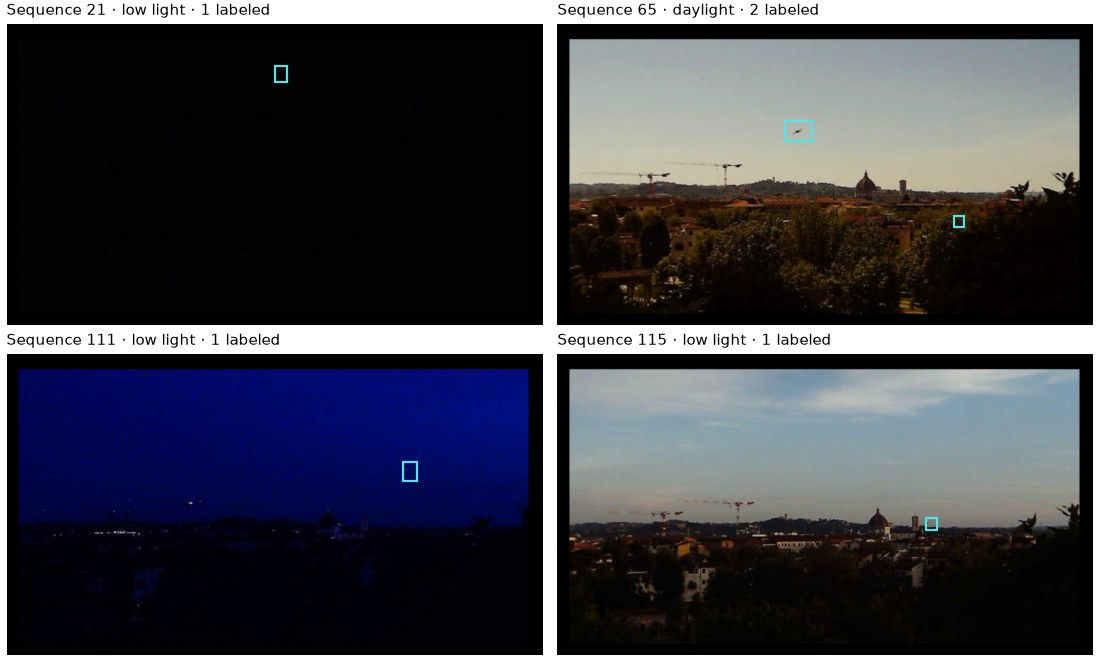

In [3]:
from matplotlib.patches import Rectangle

middle_clips = CLIPS.loc[CLIPS.index.str.endswith("-middle")].sort_values(
    "sequence_id", key=lambda values: values.astype(int),
)
fig, axes = plt.subplots(2, 2, figsize=(10, 6), layout="constrained")
for ax, (clip, metadata) in zip(axes.flat, middle_clips.iterrows(), strict=True):
    labels = reference_by_clip[clip]
    labeled_frames = sorted(labels)
    frame = labeled_frames[len(labeled_frames) // 2]
    path = DATASET / clip / "video.mp4"
    capture = cv2.VideoCapture(str(path))
    try:
        capture.set(cv2.CAP_PROP_POS_FRAMES, frame - 1)
        ok, bgr = capture.read()
    finally:
        capture.release()
    if not ok:
        raise RuntimeError(f"Could not read frame {frame} from {path}.")
    ax.imshow(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB))
    for left, top, right, bottom, *_ in labels[frame]:
        ax.add_patch(Rectangle(
            (left, top), right - left, bottom - top,
            linewidth=1.4, edgecolor="#50e5ee", facecolor="none",
        ))
    ax.set_title(
        f"Sequence {metadata['sequence_id']} · {metadata['lighting']} · "
        f"{len(labels[frame])} labeled",
        loc="left", fontsize=10,
    )
    ax.set_axis_off()

with BytesIO() as jpeg:
    fig.savefig(jpeg, format="jpeg", dpi=110, pil_kwargs={"quality": 88})
    display(Image(data=jpeg.getvalue(), format="jpeg"))
plt.close(fig)

### How FRED footage compares with the practice clips

Sequences 21 and 111 account for four of the eight FRED excerpts.
Sequence 21 is nearly black in RGB, and sequence 111 is very dark.
The earlier source-to-MP4 check found a mean absolute pixel difference
of 1.36 on a 0–255 scale. The darkness is visible in the original RGB frames.

FRED's 1280 × 720 source has about 44% as many pixels as the native
1920 × 1080 practice footage. Upscaling met the tracker's input size
while retaining the original level of detail. The table summarizes
brightness on twelve evenly spaced decoded frames per clip. The measure
is the median of each frame's mean grayscale value in the central 90%
of the image, on a 0–255 scale.

Treat the FRED scores as a stress test. As a diagnostic, the four brighter
FRED excerpts still give the boosted preset only 6 matches across 932
labeled boxes at IoU ≥ 0.50.

In [4]:
DUT_RUN = ROOT / 'preds/dut_evaluation/notebook-rerun-qb_ys_fn'
quality = pd.read_csv(DUT_RUN / "footage_quality.csv")
display(quality.set_index(["dataset", "clip"])[
    ["native_resolution", "median_mean_luma", "median_p95_luma"]
].rename(columns={
    "native_resolution": "Native resolution",
    "median_mean_luma": "Median mean grayscale",
    "median_p95_luma": "Median 95th-percentile grayscale",
}).style.format({
    "Median mean grayscale": "{:.1f}",
    "Median 95th-percentile grayscale": "{:.0f}",
}))

### Follow-up on native 1080p footage

The follow-up uses DUT Anti-UAV Tracking, a separate dataset from the
repository's documented Anti-UAV-RGBT fine-tuning source. SkyGuard's
training manifest remains undisclosed. Each source frame is an original
1920 × 1080 JPEG with a per-frame label. MP4s were encoded at the same
resolution, using 30 fps for playback because the source frame rate is
unpublished. Processing and scoring used the original frame order.
[DUT authors' repository](https://github.com/wangdongdut/DUT-Anti-UAV) ·
[Frame and annotation mirror](https://huggingface.co/datasets/aegean-ai/dut-anti-uav)

The sample uses the three shortest native 1080p sequences in full and a
360-frame window around the first absent label in video18. Selection
used sequence length and annotations before inference. These are
single-drone sequences. All three frozen presets, including v0.883
boosted, used the same settings and IoU ≥ 0.50 scoring as the FRED run.

In [5]:
dut_manifest = json.loads((DUT_RUN / "benchmark.json").read_text(encoding="utf-8"))
dut_clips = pd.DataFrame(dut_manifest["clips"]).set_index("clip")
display(Markdown(
    f"**{len(dut_clips)} clips · {dut_clips['frames'].sum():,} frames · "
    f"{dut_clips['gt_boxes'].sum():,} labeled boxes.**"
))
dut_split = pd.read_csv(DUT_RUN / "mot_overview.csv")
dut_split = dut_split[dut_split["lighting"].eq("overall")].copy()
dut_split["matches"] = dut_split["gt_boxes"] - dut_split["num_misses"]
display(dut_split.set_index("experiment")[
    ["matches", "num_false_positives", "recall", "precision", "mota", "idf1"]
].rename(columns={
    "matches": "Matches", "num_false_positives": "False positives",
    "recall": "Recall", "precision": "Precision", "mota": "MOTA", "idf1": "IDF1",
}).style.format({
    "Matches": "{:,.0f}", "False positives": "{:,.0f}",
    "Recall": "{:.2%}", "Precision": "{:.2%}", "MOTA": "{:.3f}", "IDF1": "{:.3f}",
}))
dut_per_clip = pd.read_csv(DUT_RUN / "mot_by_clip.csv")
dut_boosted = dut_per_clip.loc[dut_per_clip["experiment"].eq("v0.883-boosted")].set_index("clip")
display(Markdown("**Boosted preset by clip**"))
display(dut_boosted[["gt_boxes", "num_false_positives", "recall", "precision", "mota"]].rename(columns={
    "gt_boxes": "GT boxes", "num_false_positives": "False positives",
    "recall": "Recall", "precision": "Precision", "mota": "MOTA",
}).style.format({"Recall": "{:.2%}", "Precision": "{:.2%}", "MOTA": "{:.3f}"}))
result_href = "../" + DUT_RUN.relative_to(ROOT).as_posix()
display(Markdown(
    f"[Per-clip DUT results]({result_href}/mot_by_clip.csv) · "
    f"[DUT source manifest]({result_href}/benchmark.json) · "
    "[Prepared clips](../drone_data/dut_1080p_test/)"
))

**4 clips · 1,491 frames · 1,452 labeled boxes.**

,Matches,False positives,Recall,Precision,MOTA,IDF1
experiment,,,,,,
tracker-only,"1,205",599,82.99%,66.80%,0.415,0.671
trajectory,"1,200",556,82.64%,68.34%,0.442,0.703
v0.883-boosted,"1,366",222,94.08%,86.02%,0.787,0.897


**Boosted preset by clip**

,GT boxes,False positives,Recall,Precision,MOTA
clip,,,,,
dut-video04,341,22,95.31%,93.66%,0.883
dut-video06,200,0,100.00%,100.00%,1.000
dut-video14,590,19,90.51%,96.56%,0.873
dut-video18,321,181,95.64%,62.91%,0.393


[Per-clip DUT results](../preds/dut_evaluation/notebook-rerun-qb_ys_fn/mot_by_clip.csv) · [DUT source manifest](../preds/dut_evaluation/notebook-rerun-qb_ys_fn/benchmark.json) · [Prepared clips](../drone_data/dut_1080p_test/)

### Source archives

The four sequence downloads below are pinned to the evaluated archive versions.

In [6]:
archives = CLIPS.drop_duplicates("sequence_id")
for row in archives.itertuples():
    display(Markdown(f"[Sequence {row.sequence_id}]({row.source_url}) · SHA-256 `{row.archive_sha256}`"))

[Sequence 111](https://huggingface.co/datasets/GabrieleMagrini/FRED/resolve/295e8e5/test/111.zip) · SHA-256 `2fc4ecdadc8a4c9a207042e066a839ce3468f2c7d76cba95a49a8c53c311a132`

[Sequence 115](https://huggingface.co/datasets/GabrieleMagrini/FRED/resolve/295e8e5/test/115.zip) · SHA-256 `dc8e50dcb122b0b3c0910c239c8f1f165fc8ad33010a2f2ff4f3168cbf146a24`

[Sequence 21](https://huggingface.co/datasets/GabrieleMagrini/FRED/resolve/295e8e5/test/21.zip) · SHA-256 `80bd0348c003e12ced9d87736c1a4464d6a1446c2d70a04d7ae6a4d7f810a419`

[Sequence 65](https://huggingface.co/datasets/GabrieleMagrini/FRED/resolve/295e8e5/test/65.zip) · SHA-256 `cb468f1cea279da52ee65522d38268f0a9e96651867d2cf4730691a19a1bbbba`

### Recreate the inputs from source archives

The local clips are ready to use in `drone_data/fred_test`. To rebuild them,
download the four ZIPs above and put them in the same folder. The
[preparation script](../preds/fred_evaluation/overview-20261121-105028/prepare_fred.py)
reads RGB frames directly from those archives.

```bash
uv run python preds/fred_evaluation/overview-20261121-105028/prepare_fred.py \
  --archives /path/to/fred-archives --output drone_data/fred_test --sequences 21 111 115

uv run python preds/fred_evaluation/overview-20261121-105028/prepare_fred.py \
  --archives /path/to/fred-archives --output drone_data/fred_test --sequences 65 \
  --manifest dataset_daylight.json --lighting daylight
```

## 2. Checkpoints and pipeline

The three presets share a full-frame SkyGuard pass per lighting group at
1280 px on CPU. It saves drone candidates with confidence ≥ 0.01. Each preset
then uses the same candidate files.

The **full configured offline RGB v0.883 boosted preset** ran on all eight
excerpts. Its trajectory-guided search uses 320 px crops enlarged 2× and
the v0.883 crop checkpoint. Motion consensus then supports the verifier,
score boost and track keeper before two-drone tracking. The configured boost
raises qualifying scores from 0.10–0.30 to 0.65, with 0.30 excluded from the range.

The preset uses `--no-motion` to disable standalone motion-seeded crops.
The consensus and motion-aware keeper still use motion. This run measures
processing of recorded RGB clips on CPU.

In [7]:
display(pd.DataFrame([{
    "Preset": item["name"],
    "Crop checkpoint": Path(item["crop_weights"]).name if item["crop_weights"] else "—",
    "Tracker options": ", ".join(
        f"{name}={value}" for name, value in item["tracking_options"].items()
    ),
} for item in BENCHMARK["experiments"]]).set_index("Preset"))
for path, digest in BENCHMARK["weight_sha256"].items():
    display(Markdown(f"**{Path(path).name}** · SHA-256 `{digest}`"))

,Crop checkpoint,Tracker options
Preset,,
tracker-only,—,"high=0.6, low=0.05, new=0.3, confirm=3, coast=3"
trajectory,skyguard-best.pt,"crop=320, crop-imgsz=320, no-motion=True"
v0.883-boosted,epoch0.pt,"crop=320, crop-imgsz=320, crop-scale=2, no-mot..."


**skyguard-best.pt** · SHA-256 `33f5bc2309b61427ee77a00110c0b01cf7f03912b3f4f2fa65ca2793c2550f90`

**epoch0.pt** · SHA-256 `9abbc7a4c1ffc9c7bfda8b04081a8effe366c42d1a146909a932c694b3b73668`

### Run inference again

Set `RUN_MODE` in the configuration cell and run the notebook from the top.
The rerun invokes the repository's detection and tracking scripts and writes a
new results directory under `preds/fred_evaluation`. The saved benchmark records
settings and weights by SHA-256 so a rerun can verify them. Leave
`RERUN_CLIPS` empty for the complete evaluation or select a subset for a quick check.

In [8]:
def rerun_benchmark(root, dataset, benchmark, selected_names=()):
    """Run the archived presets on the prepared benchmark clips."""
    import hashlib
    import shlex
    import shutil
    import subprocess
    import sys
    import tempfile
    from pathlib import Path
    from time import perf_counter

    import cv2
    import motmetrics as mm
    import pandas as pd

    from eval_track import load_ids, mot
    from score import evaluate

    root = Path(root).resolve()
    dataset = (root / dataset).resolve()
    clips = {clip["clip"]: clip for clip in benchmark["clips"]}
    unknown = set(selected_names) - clips.keys()
    if unknown:
        raise ValueError(f"Unknown benchmark clips: {', '.join(sorted(unknown))}")
    selected = [name for name in clips if not selected_names or name in selected_names]
    expected_size = tuple(benchmark["converted_size_xy"])
    ground_truth = {}
    groups = {}
    for name in selected:
        video = dataset / name / "video.mp4"
        labels = dataset / name / "gt" / "gt.txt"
        for path in (video, labels):
            if not path.is_file():
                raise FileNotFoundError(f"Missing prepared FRED input: {path}")
        with_video = cv2.VideoCapture(str(video))
        try:
            size = tuple(int(with_video.get(prop)) for prop in (
                cv2.CAP_PROP_FRAME_WIDTH, cv2.CAP_PROP_FRAME_HEIGHT
            ))
            frames = int(with_video.get(cv2.CAP_PROP_FRAME_COUNT))
            fps = with_video.get(cv2.CAP_PROP_FPS)
        finally:
            with_video.release()
        clip = clips[name]
        if size != expected_size or frames != clip["frames"] or abs(fps - benchmark["fps"]) > 0.05:
            raise ValueError(f"{video} has {size}, {frames} frames, {fps:g} FPS")
        truth = load_ids(labels, False)
        if sum(map(len, truth.values())) != clip["gt_boxes"] or any(
            not 1 <= frame <= frames for frame in truth
        ):
            raise ValueError(f"Ground-truth counts or frame indices differ from the manifest: {labels}")
        ground_truth[name] = truth
        groups.setdefault(clip["lighting"], []).append(name)

    def checkpoint(recorded):
        original = Path(recorded).expanduser()
        filename = original.name
        target_hash = benchmark["weight_sha256"][recorded]
        candidates = [root / original]
        if filename == "skyguard-best.pt":
            candidates.extend([
                root.parent / "CF Drone trecking " / "models" / filename,
                root.parent / "pretrained" / "drone-detection-yolov11" / "best.pt",
                root / "models" / filename,
            ])
        elif filename == "epoch0.pt":
            candidates.append(root / "runs" / "ft_1280" / "weights" / filename)
        for candidate in dict.fromkeys(candidates):
            if candidate.is_file():
                with candidate.open("rb") as stream:
                    if hashlib.file_digest(stream, "sha256").hexdigest() == target_hash:
                        return candidate.resolve()
        raise FileNotFoundError(f"Could not find checkpoint matching {target_hash}: {recorded}")

    experiments = benchmark["experiments"]
    stages = {"tracker": "run_tracker.py", "trajectory": "pipeline.py", "boosted": "pipeline_boost.py"}
    detector_keys = ("detector_weights", "imgsz", "conf", "keep_classes", "device")
    if len({tuple(item[key] for key in detector_keys) for item in experiments}) != 1:
        raise ValueError("The archived presets must share a single detector configuration")
    detector = experiments[0]
    full_weights = checkpoint(detector["detector_weights"])
    crops = {
        item["name"]: checkpoint(item["crop_weights"])
        for item in experiments if item["crop_weights"]
    }

    destination = root / "preds" / "fred_evaluation"
    destination.mkdir(parents=True, exist_ok=True)
    run = Path(tempfile.mkdtemp(prefix="notebook-rerun-", dir=destination))
    logs = run / "logs"
    logs.mkdir()
    detections = run / "detections"
    detections.mkdir()
    tracks = {item["name"]: run / f"tracks-{item['name']}" for item in experiments}
    for directory in tracks.values():
        directory.mkdir()

    def stage(script, args, tag):
        command = [sys.executable, "-u", str(root / script), *map(str, args)]
        print(f"{tag} · {script}", flush=True)
        start = perf_counter()
        log = logs / f"{tag}.log"
        with log.open("w", encoding="utf-8") as stream:
            stream.write(shlex.join(command) + "\n\n")
            with subprocess.Popen(
                command, cwd=root, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                text=True, errors="replace", bufsize=1,
            ) as process:
                try:
                    for line in process.stdout:
                        print(line, end="", flush=True)
                        stream.write(line)
                    status = process.wait()
                except KeyboardInterrupt:
                    process.terminate()
                    raise
        if status:
            raise RuntimeError(f"{script} exited with status {status}. See {log}.")
        return perf_counter() - start

    def collect(source, target, names):
        expected = {f"{name}.txt" for name in names}
        actual = {file.name for file in source.glob("*.txt")}
        if actual != expected:
            raise RuntimeError(f"Unexpected prediction files in {source}: {actual ^ expected}")
        for filename in sorted(expected):
            shutil.move(source / filename, target / filename)

    timings = []
    for lighting, names in groups.items():
        tag = lighting.replace(" ", "-")
        with tempfile.TemporaryDirectory(prefix=f"{tag}-inputs-", dir=run) as temporary:
            stage_dir = Path(temporary)
            inputs = stage_dir / "videos"
            inputs.mkdir()
            for name in names:
                (inputs / name).symlink_to((dataset / name).resolve(), target_is_directory=True)
            raw = stage_dir / "detections"
            detector_time = stage("run_video.py", [
                "--weights", full_weights, "--videos", inputs, "--out", raw,
                "--imgsz", detector["imgsz"], "--conf", detector["conf"],
                "--keep", detector["keep_classes"], "--device", detector["device"],
            ], f"{tag}-detector")
            for index, item in enumerate(experiments):
                name = item["name"]
                predicted = stage_dir / f"tracks-{name}"
                args = ["--videos", inputs, "--dets", raw, "--out", predicted]
                if name in crops:
                    args.extend(["--weights", crops[name], "--device", item["device"]])
                for option, value in item["tracking_options"].items():
                    if value is not False and value is not None:
                        args.append(f"--{option}")
                        if value is not True:
                            args.append(value)
                track_time = stage(stages[item["pipeline"]], args, f"{tag}-{name}")
                collect(predicted, tracks[name], names)
                timings.append({
                    "lighting": lighting, "experiment": name, "detection_s": detector_time,
                    "tracking_s": track_time, "combined_s": detector_time + track_time,
                    "detections_reused": index > 0,
                })
            collect(raw, detections, names)

    metrics = ["mota", "idf1", "precision", "recall", "num_switches", "num_false_positives", "num_misses"]
    overview = []
    per_clip = {}
    scorer = mm.metrics.create()
    for experiment, directory in tracks.items():
        accumulators = {}
        ap50 = {}
        for name in selected:
            truth = ground_truth[name]
            prediction = load_ids(directory / f"{name}.txt", True)
            accumulators[name] = mot(truth, prediction, 0.0)
            ap50[name] = evaluate(truth, prediction, 0.5)[0]
        for lighting, names in {"overall": selected, **groups}.items():
            scores = scorer.compute_many(
                [accumulators[name] for name in names], names=names,
                metrics=metrics, generate_overall=True,
            )
            scores["AP50"] = [*(ap50[name] for name in names), sum(ap50[name] for name in names) / len(names)]
            if lighting == "overall":
                per_clip[experiment] = scores.drop(index="OVERALL").assign(
                    lighting=[clips[name]["lighting"] for name in names],
                    gt_boxes=[clips[name]["gt_boxes"] for name in names],
                )
            overview.append({
                "experiment": experiment, "lighting": lighting, "clips": len(names),
                "frames": sum(clips[name]["frames"] for name in names),
                "gt_boxes": sum(clips[name]["gt_boxes"] for name in names),
                **scores.loc["OVERALL"].to_dict(),
            })

    pd.concat(per_clip, names=["experiment", "clip"]).to_csv(run / "mot_by_clip.csv")
    pd.DataFrame(overview).to_csv(run / "mot_overview.csv", index=False)
    pd.DataFrame(timings).to_csv(run / "timings.csv", index=False)
    print(f"Saved benchmark metrics to {run}", flush=True)
    return run

In [9]:
if RUN_MODE == "rerun":
    RESULTS = rerun_benchmark(ROOT, DATASET, BENCHMARK, RERUN_CLIPS)
else:
    RESULTS = SAVED_RUN

required = ("mot_overview.csv", "mot_by_clip.csv", "timings.csv")
missing = [name for name in required if not (RESULTS / name).is_file()]
if missing:
    raise FileNotFoundError(f"Missing {', '.join(missing)} under {RESULTS}. Set RUN_MODE to 'rerun' to regenerate.")
mot_overview = pd.read_csv(RESULTS / "mot_overview.csv")
mot_by_clip = pd.read_csv(RESULTS / "mot_by_clip.csv")
timings = pd.read_csv(RESULTS / "timings.csv")
evaluated_clips = sorted(mot_by_clip["clip"].unique())
print(f"{RUN_MODE.capitalize()} run · {len(evaluated_clips)} excerpts")
print(RESULTS.relative_to(ROOT))

Saved run · 8 excerpts
preds/fred_evaluation/overview-20261121-105028


### Boost activity in the run logs

These counters record pipeline actions before matching against the reference
boxes. Crop rates are rounded by the pipeline. The three presets differ
in several settings, so their comparison measures each preset as a whole.

In [10]:
import re

if RUN_MODE == "saved":
    boost_logs = [
        ROOT / folder / "configs" / "v0.883-boosted" / "track.log"
        for folder in BENCHMARK.get("source_runs", {}).values()
    ]
else:
    boost_logs = sorted((RESULTS / "logs").glob("*-v0.883-boosted.log"))

boost_line = re.compile(
    r"^(?P<clip>[^:\n]+): (?P<frames>\d+) frames, prediction crops/frame "
    r"(?P<crops>[\d.]+), .*?verified-down (?P<down>\d+), "
    r"kept (?P<kept>\d+), boosted (?P<boosted>\d+),",
    re.MULTILINE,
)
activity = {}
for log in boost_logs:
    try:
        log_text = log.read_text(encoding="utf-8", errors="replace")
    except OSError:
        continue
    for hit in boost_line.finditer(log_text):
        row = hit.groupdict()
        if row["clip"] in evaluated_clips:
            activity[row["clip"]] = {
                "Frames": int(row["frames"]),
                "Prediction crops per frame": float(row["crops"]),
                "Scores lowered": int(row["down"]),
                "Scores boosted": int(row["boosted"]),
                "Keeper continuations": int(row["kept"]),
            }

if activity:
    boost_table = pd.DataFrame.from_dict(activity, orient="index").rename_axis("Excerpt")
    boost_table = boost_table.loc[[clip for clip in evaluated_clips if clip in activity]]
    display(boost_table.style.format({"Prediction crops per frame": "{:.2f}"}))
    totals = boost_table.sum()
    display(Markdown(
        f"Across **{int(totals['Frames']):,} logged frames**, the preset boosted "
        f"**{int(totals['Scores boosted']):,} scores**, lowered "
        f"**{int(totals['Scores lowered']):,} scores**, and recorded "
        f"**{int(totals['Keeper continuations']):,} keeper continuations**. "
        "These counts describe pipeline activity before tracking metrics are scored."
    ))

missing_logs = [clip for clip in evaluated_clips if clip not in activity]
if missing_logs:
    print(f"Boost activity log unavailable for {', '.join(missing_logs)}.")

,Frames,Prediction crops per frame,Scores lowered,Scores boosted,Keeper continuations
Excerpt,,,,,
fred-111-entry,180,0.00,571,1,0
fred-111-middle,180,0.00,184,2,0
fred-115-entry,180,0.09,465,6,5
fred-115-middle,180,0.20,508,0,0
fred-21-entry,180,0.00,0,0,0
fred-21-middle,180,0.00,0,0,0
fred-65-entry,180,0.05,361,5,0
fred-65-middle,180,0.03,723,1,0


Across **1,440 logged frames**, the preset boosted **15 scores**, lowered **2,812 scores**, and recorded **5 keeper continuations**. These counts describe pipeline activity before tracking metrics are scored.

## 3. Tracking accuracy

A tracker box must have intersection over union (IoU) of at least 0.50 with a
reference box to match. All tracker outputs enter scoring. Recall is matched
reference boxes divided by labeled boxes, and precision is correct matches
divided by emitted boxes. Precision is undefined for a clip with zero outputs.

MOTA is one minus the sum of misses, false positives and ID switches divided
by reference detections. IDF1 measures how well the output maintains the
reference identities. Precision, recall, MOTA and IDF1 are pooled across the
included clips. AP50 is the repository's mean of per-clip AP at IoU 0.50.

In [11]:
def tracking_table(rows, keys):
    rows = rows.copy()
    rows["matches"] = rows["gt_boxes"] - rows["num_misses"]
    table = rows.set_index(keys)[[
        "gt_boxes", "matches", "num_misses", "num_false_positives", "num_switches",
        "precision", "recall", "mota", "idf1", "AP50",
    ]].rename(columns={
        "gt_boxes": "GT boxes", "matches": "Matches", "num_misses": "Misses",
        "num_false_positives": "False positives", "num_switches": "ID switches",
        "precision": "Precision", "recall": "Recall", "mota": "MOTA", "idf1": "IDF1",
    })
    return table.style.format({
        "GT boxes": "{:,.0f}", "Matches": "{:,.0f}", "Misses": "{:,.0f}",
        "False positives": "{:,.0f}", "ID switches": "{:,.0f}",
        "Precision": "{:.2%}", "Recall": "{:.2%}", "MOTA": "{:.3f}", "IDF1": "{:.3f}",
        "AP50": "{:.5f}",
    }, na_rep="—")

overall = mot_overview.loc[mot_overview["lighting"].eq("overall")]
display(tracking_table(overall, ["experiment"]))
display(tracking_table(mot_overview.loc[mot_overview["lighting"].ne("overall")], ["lighting", "experiment"]))

,GT boxes,Matches,Misses,False positives,ID switches,Precision,Recall,MOTA,IDF1,AP50
experiment,,,,,,,,,,
tracker-only,"1,337",6,"1,331",528,0,1.12%,0.45%,-0.390,0.006,0.00010
trajectory,"1,337",6,"1,331",658,0,0.90%,0.45%,-0.488,0.006,0.00009
v0.883-boosted,"1,337",6,"1,331",543,0,1.09%,0.45%,-0.402,0.006,0.00009


,,GT boxes,Matches,Misses,False positives,ID switches,Precision,Recall,MOTA,IDF1,AP50
lighting,experiment,,,,,,,,,,
low light,tracker-only,746,0,746,283,0,0.00%,0.00%,-0.379,0.000,0.00000
daylight,tracker-only,591,6,585,245,0,2.39%,1.02%,-0.404,0.014,0.00038
low light,trajectory,746,0,746,292,0,0.00%,0.00%,-0.391,0.000,0.00000
daylight,trajectory,591,6,585,366,0,1.61%,1.02%,-0.609,0.012,0.00038
low light,v0.883-boosted,746,0,746,296,0,0.00%,0.00%,-0.397,0.000,0.00000
daylight,v0.883-boosted,591,6,585,247,0,2.37%,1.02%,-0.408,0.014,0.00038


In [12]:
display(tracking_table(mot_by_clip.sort_values(["clip", "experiment"]), ["clip", "experiment"]))

### Context from the practice clips

The saved practice run used the same named presets on the repository's local
practice footage. The FRED sample changes the lighting, scenes and targets
together, so the score difference measures transfer to these clips.

In [13]:
if PRACTICE_SCORES.is_file():
    practice = pd.read_csv(PRACTICE_SCORES)
    practice = practice.loc[practice["clip"].eq("OVERALL")].set_index("experiment")
    fred = overall.set_index("experiment")
    comparison = pd.concat(
        {"Practice": practice[["mota", "recall"]], "FRED": fred[["mota", "recall"]]},
        axis=1,
    ).reindex(PRESETS)
    display(comparison.style.format({
        (dataset, metric): "{:.3f}" if metric == "mota" else "{:.2%}"
        for dataset, metric in comparison.columns
    }))
else:
    print("The local practice score file is unavailable.")

## 4. Full-frame detector and overlap sensitivity

Raw SkyGuard candidates use a shared dummy track ID. The detector analysis
scores boxes per frame without using identity. At each cutoff it finds
one-to-one matches at the chosen overlap threshold, maximizing valid matches
first. The confidence cutoffs of 0.30 and 0.60 match the bird-image evaluation.

The overlap sweep also recomputes box matches for each tracker while holding
its output fixed. The relaxed cutoffs help show how many boxes landed near a
labeled drone. The tracking scores above use the standard 0.50 cutoff.

In [14]:
IOU_LEVELS = (0.10, 0.30, 0.50)
DETECTOR_CUTOFFS = (0.01, 0.30, 0.60)
truth = {}
raw = {}
tracked = {name: {} for name in PRESETS}


def read_boxes(path, has_confidence):
    if not path.is_file():
        raise FileNotFoundError(path)
    return load_ids(path, has_confidence)


def overlap_count(reference, predictions, minimum_iou):
    if not reference or not predictions:
        return 0
    overlaps = np.array([[iou(gt, pred) for pred in predictions] for gt in reference])
    valid = overlaps >= minimum_iou
    # A single invalid pair costs more than all valid pairs combined.
    cost = np.where(valid, 1 - overlaps, min(overlaps.shape) + 1)
    rows, columns = linear_sum_assignment(cost)
    return int(valid[rows, columns].sum())


def score_matches(ground_truth, predictions, min_confidence):
    filtered = {frame: [box for box in boxes if box[4] >= min_confidence]
                for frame, boxes in predictions.items()}
    count = sum(len(boxes) for boxes in filtered.values())
    matches = {
        iou_level: sum(overlap_count(boxes, filtered.get(frame, ()), iou_level)
                       for frame, boxes in ground_truth.items())
        for iou_level in IOU_LEVELS
    }
    return count, matches


sensitivity_rows = []
detector_rows = []
for clip in evaluated_clips:
    truth[clip] = reference_by_clip[clip]
    raw[clip] = read_boxes(RESULTS / "detections" / f"{clip}.txt", True)
    for preset in PRESETS:
        tracked[preset][clip] = read_boxes(RESULTS / f"tracks-{preset}" / f"{clip}.txt", True)
    gt_count = sum(map(len, truth[clip].values()))
    assert gt_count == CLIPS.loc[clip, "gt_boxes"], clip
    ap50 = evaluate(
        {frame: [box[:5] for box in boxes] for frame, boxes in truth[clip].items()},
        {frame: [box[:5] for box in boxes] for frame, boxes in raw[clip].items()},
        0.50,
    )[0]

    variants = [("detections", cutoff, raw[clip]) for cutoff in DETECTOR_CUTOFFS]
    variants.extend((f"tracks-{preset}", 0.0, tracked[preset][clip]) for preset in PRESETS)
    for variant, cutoff, predictions in variants:
        count, matches = score_matches(truth[clip], predictions, cutoff)
        sensitivity_rows.extend({
            "clip": clip, "lighting": CLIPS.loc[clip, "lighting"], "variant": variant,
            "confidence": cutoff, "iou_threshold": iou_level,
            "matches": n_matches, "gt_boxes": gt_count,
        } for iou_level, n_matches in matches.items())
        if variant == "detections" and cutoff in (0.30, 0.60):
            tp = matches[0.50]
            detector_rows.append({
                "clip": clip, "confidence": cutoff, "gt_boxes": gt_count, "tp": tp,
                "fp": count - tp, "misses": gt_count - tp, "ap50_unfiltered": ap50,
            })

sensitivity = pd.DataFrame(sensitivity_rows)
detector = pd.DataFrame(detector_rows)
pooled_detector = detector.groupby("confidence", as_index=False).agg(
    gt_boxes=("gt_boxes", "sum"), tp=("tp", "sum"), fp=("fp", "sum"),
    misses=("misses", "sum"), ap50_unfiltered=("ap50_unfiltered", "mean"),
)
detector = pd.concat([detector, pooled_detector.assign(clip="OVERALL")], ignore_index=True)
detector["precision"] = detector["tp"] / (detector["tp"] + detector["fp"])
detector["recall"] = detector["tp"] / detector["gt_boxes"]
detector = detector[["clip", "confidence", "gt_boxes", "tp", "fp", "misses",
                     "precision", "recall", "ap50_unfiltered"]]

if RUN_MODE == "rerun":
    detector.to_csv(RESULTS / "detector_metrics.csv", index=False)
    sensitivity.to_csv(RESULTS / "match_sensitivity.csv", index=False)
else:
    for label, actual, keys in (
        ("detector_metrics", detector, ["clip", "confidence"]),
        ("match_sensitivity", sensitivity, ["clip", "variant", "confidence", "iou_threshold"]),
    ):
        archived = pd.read_csv(SAVED_RUN / f"{label}.csv")
        pd.testing.assert_frame_equal(
            actual.sort_values(keys).reset_index(drop=True),
            archived.sort_values(keys).reset_index(drop=True),
            check_dtype=False,
        )

In [15]:
def detector_table(rows):
    return rows.set_index(["clip", "confidence"]).rename(columns={
        "gt_boxes": "GT boxes", "tp": "Matches", "fp": "False positives", "misses": "Misses",
        "precision": "Precision", "recall": "Recall", "ap50_unfiltered": "AP50 (all candidates)",
    }).style.format({
        "Precision": "{:.2%}", "Recall": "{:.2%}", "AP50 (all candidates)": "{:.5f}",
    }, na_rep="—")

display(detector_table(detector.loc[detector["clip"].eq("OVERALL")]))
display(detector_table(detector.loc[detector["clip"].ne("OVERALL")]))

IoU cutoff · matching boxes,0.1,0.3,0.5
Setting,,,
Raw SkyGuard ≥ 0.01,497,200,32
Raw SkyGuard ≥ 0.30,423,121,8
Raw SkyGuard ≥ 0.60,325,111,5
tracker-only,372,110,6
trajectory,376,109,6
v0.883-boosted,378,110,6


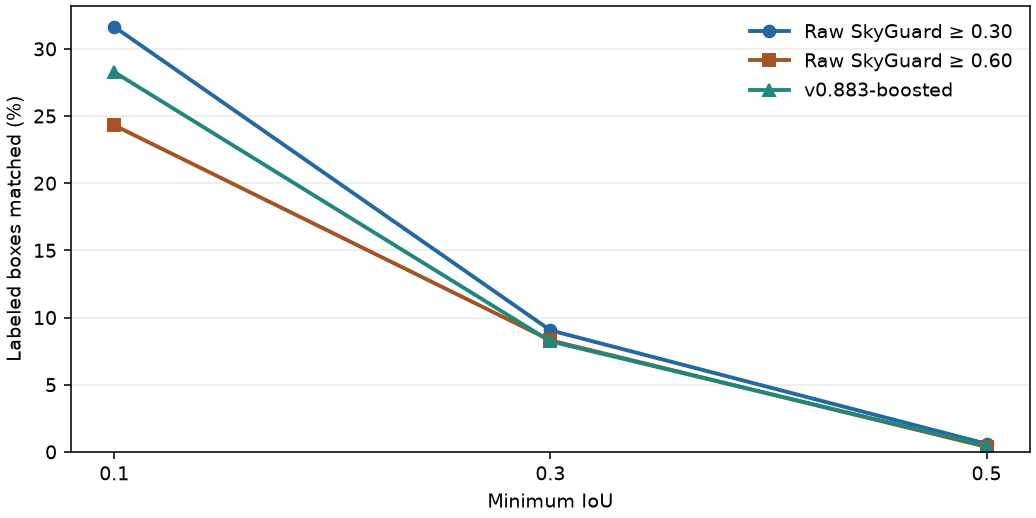

In [16]:
pooled_sensitivity = sensitivity.groupby(
    ["variant", "confidence", "iou_threshold"], as_index=False,
)[["matches", "gt_boxes"]].sum()
pooled_sensitivity["recall"] = pooled_sensitivity["matches"] / pooled_sensitivity["gt_boxes"]

def sensitivity_label(variant, confidence):
    return f"Raw SkyGuard ≥ {confidence:.2f}" if variant == "detections" else variant.removeprefix("tracks-")

pooled_sensitivity["setting"] = [
    sensitivity_label(row.variant, row.confidence) for row in pooled_sensitivity.itertuples()
]
display(pooled_sensitivity.pivot(
    index="setting", columns="iou_threshold", values="matches"
).rename_axis(index="Setting", columns="IoU cutoff · matching boxes"))

fig, ax = plt.subplots(figsize=(7.4, 3.7), layout="constrained")
for setting, color, marker in [
    ("Raw SkyGuard ≥ 0.30", "#2468a2", "o"),
    ("Raw SkyGuard ≥ 0.60", "#a65323", "s"),
    ("v0.883-boosted", "#20877e", "^"),
]:
    series = pooled_sensitivity.loc[pooled_sensitivity["setting"].eq(setting)].sort_values("iou_threshold")
    ax.plot(series["iou_threshold"], series["recall"] * 100, marker=marker, linewidth=2,
            label=setting, color=color)
ax.set(xticks=IOU_LEVELS, xlabel="Minimum IoU", ylabel="Labeled boxes matched (%)", ylim=(0, None))
ax.grid(axis="y", alpha=0.25)
ax.legend(frameon=False)
with BytesIO() as png:
    fig.savefig(png, format="png", dpi=140)
    display(Image(data=png.getvalue(), format="png"))
plt.close(fig)

## 5. Runtime

Timing includes process startup, video decoding and writing predictions.
Detection is measured once for each lighting group. The combined column shows
the measured detection cost plus the tracking cost for each preset.

In [17]:
display(timings.set_index(["lighting", "experiment"]).rename(columns={
    "detection_s": "Full-frame detection (s)", "tracking_s": "Tracking (s)",
    "combined_s": "Combined (s)", "detections_reused": "Shared detections reused",
}).style.format({
    "Full-frame detection (s)": "{:.2f}", "Tracking (s)": "{:.2f}", "Combined (s)": "{:.2f}",
}))

## 6. Source and conversion check

The original run sampled 12 evenly spaced frames per excerpt. SkyGuard ran on
the original RGB JPEGs and the converted MP4 detections were checked at the
same frame numbers. This compares IoU 0.50 match counts on the 96 sampled
frames. Mean pixel error is the mean absolute difference between the
decoded MP4 and the original JPEG resized to 1920 × 1080, on a 0–255 scale.

In [18]:
conversion_path = SAVED_RUN / "conversion_check.csv"
if conversion_path.is_file():
    conversion = pd.read_csv(conversion_path)
    conversion_by_clip = conversion.groupby("clip").agg(
        frames=("frame", "size"), gt_boxes=("gt_boxes", "sum"),
        native_matches=("native_iou50_matches", "sum"),
        converted_matches=("converted_iou50_matches", "sum"),
        mean_pixel_error=("mp4_mean_pixel_error", "mean"),
    )
    conversion_by_clip.loc["OVERALL"] = {
        "frames": len(conversion), "gt_boxes": conversion["gt_boxes"].sum(),
        "native_matches": conversion["native_iou50_matches"].sum(),
        "converted_matches": conversion["converted_iou50_matches"].sum(),
        "mean_pixel_error": conversion["mp4_mean_pixel_error"].mean(),
    }
    display(conversion_by_clip.style.format({
        "frames": "{:.0f}", "gt_boxes": "{:.0f}", "native_matches": "{:.0f}",
        "converted_matches": "{:.0f}", "mean_pixel_error": "{:.2f}",
    }))
else:
    print("The original JPEG-to-MP4 check is available in the archived results folder.")

,frames,gt_boxes,native_matches,converted_matches,mean_pixel_error
clip,,,,,
fred-111-entry,12,4,0,0,1.38
fred-111-middle,12,12,0,0,1.41
fred-115-entry,12,10,0,0,1.49
fred-115-middle,12,12,0,0,1.52
fred-21-entry,12,3,0,0,0.93
fred-21-middle,12,8,0,0,0.93
fred-65-entry,12,19,1,1,1.62
fred-65-middle,12,20,0,0,1.59
OVERALL,96,88,1,1,1.36


## 7. Annotated frames

Cyan shows reference boxes. Orange shows tracker output and confidence.
Each image shows the middle labeled frame for its excerpt. Change
`PREVIEW_CLIPS` or `PREVIEW_PRESET` in the configuration cell to inspect another
part of the run.

**fred-65-entry** · frame 106 · v0.883-boosted

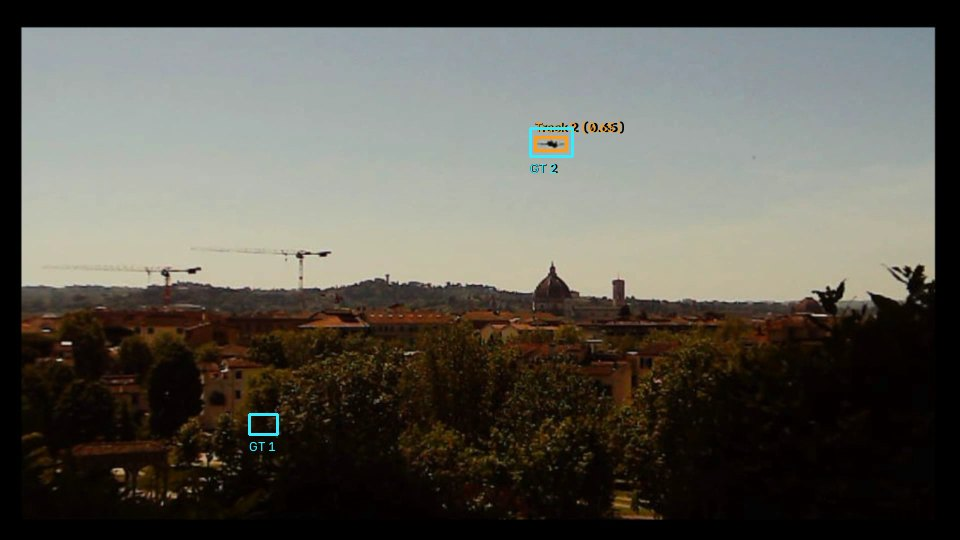

**fred-115-middle** · frame 91 · v0.883-boosted

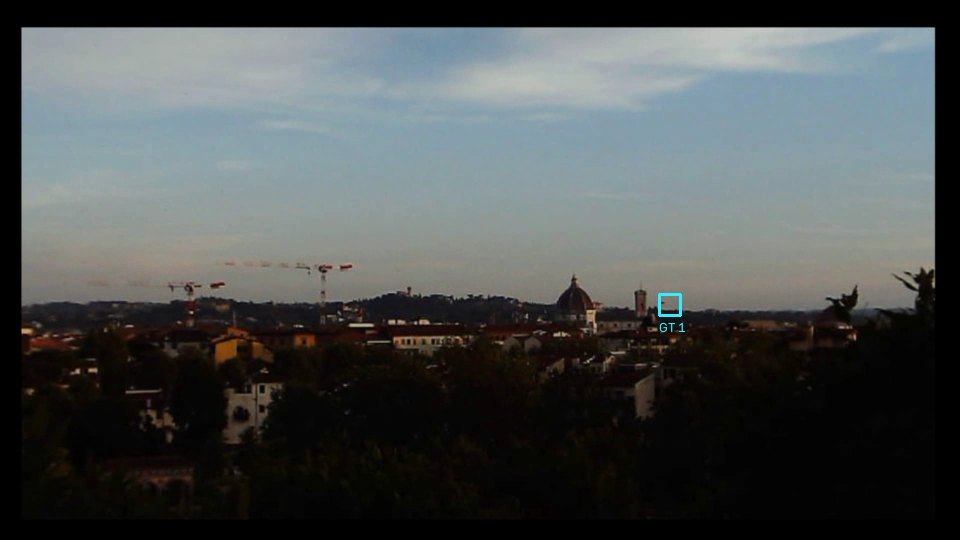

**fred-21-middle** · frame 64 · v0.883-boosted

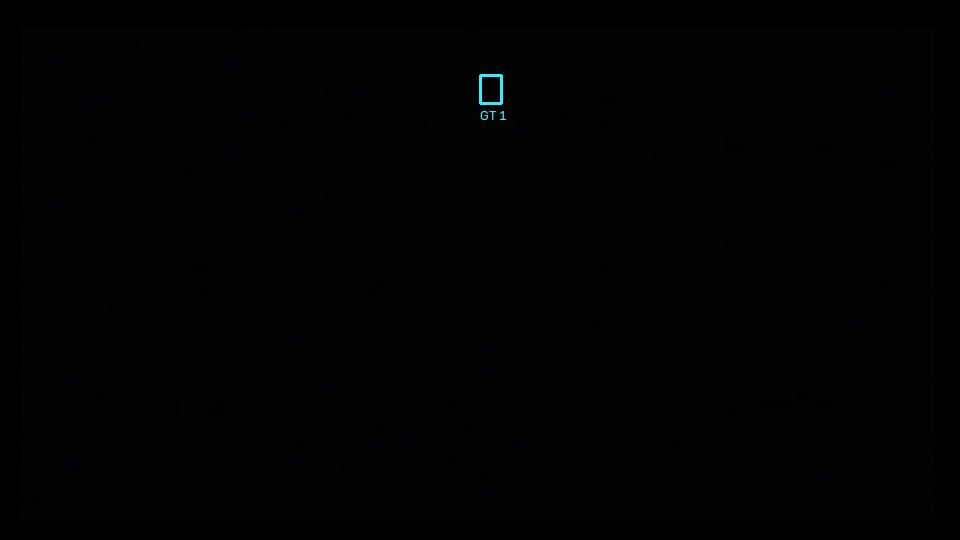

In [19]:
def annotate_boxes(image, boxes, scale, *, reference):
    color = (255, 235, 55) if reference else (20, 155, 255)
    font = cv2.FONT_HERSHEY_SIMPLEX
    height, width = image.shape[:2]
    for x1, y1, x2, y2, confidence, target_id in boxes:
        left, right = (min(max(round(x * scale), 0), width - 1) for x in (x1, x2))
        top, bottom = (min(max(round(y * scale), 0), height - 1) for y in (y1, y2))
        caption = f"GT {target_id}" if reference else f"Track {target_id} ({confidence:.2f})"
        (label_width, label_height), _ = cv2.getTextSize(caption, font, 0.45, 1)
        text_x = min(left, max(width - label_width - 3, 0))
        text_y = bottom + label_height + 5 if reference else top - 5
        text_y = max(label_height + 2, min(height - 4, text_y))
        cv2.rectangle(image, (left, top), (right, bottom), color, 2)
        cv2.putText(image, caption, (text_x, text_y), font, 0.45, (0, 0, 0), 3)
        cv2.putText(image, caption, (text_x, text_y), font, 0.45, color, 1)


if PREVIEW_PRESET not in PRESETS:
    raise ValueError(f"Choose PREVIEW_PRESET from {PRESETS}.")
for clip in (tuple(name for name in PREVIEW_CLIPS if name in evaluated_clips) or evaluated_clips[:1]):
    labeled_frames = sorted(truth[clip])
    frame = labeled_frames[len(labeled_frames) // 2] if labeled_frames else 1
    path = DATASET / clip / "video.mp4"
    capture = cv2.VideoCapture(str(path))
    try:
        capture.set(cv2.CAP_PROP_POS_FRAMES, frame - 1)
        ok, image = capture.read()
    finally:
        capture.release()
    if not ok:
        raise RuntimeError(f"Could not read frame {frame} from {path}.")
    scale = min(1, 960 / image.shape[1])
    image = cv2.resize(image, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
    annotate_boxes(image, tracked[PREVIEW_PRESET][clip].get(frame, ()), scale, reference=False)
    annotate_boxes(image, truth[clip].get(frame, ()), scale, reference=True)
    ok, jpeg = cv2.imencode(".jpg", image, [cv2.IMWRITE_JPEG_QUALITY, 86])
    if not ok:
        raise RuntimeError(f"Could not encode {clip}, frame {frame}.")
    display(Markdown(f"**{clip}** · frame {frame} · {PREVIEW_PRESET}"))
    display(Image(data=jpeg.tobytes(), format="jpeg"))

## 8. What the saved run shows

All three presets matched 6 of 1,337 labeled boxes at IoU ≥ 0.50. The six
matches came from `fred-65-entry`, one daylight excerpt. The boosted preset
matched 110 labels at IoU ≥ 0.30, which shows that a looser overlap threshold
recovers some detections. The raw detector also had low recall, including
before the tracker filtered its boxes.

The boosted preset reached 0.883 MOTA on local practice footage and −0.402
on this FRED sample. These are separate clips with different scenes,
lighting and targets. The comparison shows weak transfer to this sample.

In [20]:
for filename, label in [
    ("mot_overview.csv", "Pooled and lighting-level tracking scores"),
    ("mot_by_clip.csv", "Per-clip tracking scores"),
    ("detector_metrics.csv", "Detector confidence cutoffs"),
    ("match_sensitivity.csv", "Box-overlap sweep"),
    ("timings.csv", "Stage timings"),
]:
    target = RESULTS / filename
    if target.is_file():
        relative = "../" + target.relative_to(ROOT).as_posix()
        display(Markdown(f"[{label}]({relative})"))
for filename, label in [
    ("benchmark.json", "Source and checkpoint manifest"),
    ("conversion_check.csv", "Source conversion sample checks"),
]:
    target = SAVED_RUN / filename
    if target.is_file():
        display(Markdown(f"[{label}](../{target.relative_to(ROOT).as_posix()})"))

[Pooled and lighting-level tracking scores](../preds/fred_evaluation/overview-20261121-105028/mot_overview.csv)

[Per-clip tracking scores](../preds/fred_evaluation/overview-20261121-105028/mot_by_clip.csv)

[Detector confidence cutoffs](../preds/fred_evaluation/overview-20261121-105028/detector_metrics.csv)

[Box-overlap sweep](../preds/fred_evaluation/overview-20261121-105028/match_sensitivity.csv)

[Stage timings](../preds/fred_evaluation/overview-20261121-105028/timings.csv)

[Source and checkpoint manifest](../preds/fred_evaluation/overview-20261121-105028/benchmark.json)

[Source conversion sample checks](../preds/fred_evaluation/overview-20261121-105028/conversion_check.csv)